# 1. Setup and Data Loading


Import the libraries and define the main project paths.

## 1.1 Imports and Paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = (
    INTERIM_DATA_DIR / "final_clean_metadata.csv"
)

## 1.2 Load Metadata

Load the cleaned dataset metadata created in the previous notebook.

In [3]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (16962, 12)


,sequence,image_sequence,file,label,site,date,camera,project_class,split,zip_path,found_in_zip,quality_status
0,77378,image2,1106150852100835S082.jpg,BIRD,835,6/11/2015 8:52,S08,BIRD,train,images/1106150852100835S082.jpg,False,keep
1,41636,image3,210916072714043as433.jpg,BIRD,043a,9/21/2016 7:27,s43,BIRD,train,images/210916072714043as433.jpg,False,keep
2,58458,image2,240916111910017as082.jpg,BIRD,017a,9/24/2016 11:19,s08,BIRD,train,images/240916111910017as082.jpg,False,keep
3,36044,image2,161016171542019b9705.jpg,BIRD,019b,10/16/2016 17:15,970,BIRD,train,images/161016171542019b9705.jpg,False,keep
4,38018,image2,021116133626027cs082.jpg,BIRD,027c,11/2/2016 13:36,s08,BIRD,train,images/021116133626027cs082.jpg,False,keep


In [4]:
pd.crosstab(
    df["project_class"],
    df["split"]
)

split,test,train,val
project_class,,,
BIRD,448,1869,419
CAT,450,1999,402
EMPTY,444,1904,418
HEDGEHOG,450,1953,396
POSSUM,450,2064,450
RODENT,450,2011,385


#### Class Balance After Cleaning

The final dataset has small differences in class size because low-quality images were removed.

The class distribution is still relatively balanced, so no additional resampling is applied.

## 1.3 Define Classes and Device

Define the six classes used in the classification model.

In [5]:
CLASS_NAMES = [
    "BIRD",
    "CAT",
    "EMPTY",
    "HEDGEHOG",
    "POSSUM",
    "RODENT"
]

CLASS_TO_INDEX = {
    cls: idx
    for idx, cls in enumerate(CLASS_NAMES)
}

CLASS_TO_INDEX

{'BIRD': 0, 'CAT': 1, 'EMPTY': 2, 'HEDGEHOG': 3, 'POSSUM': 4, 'RODENT': 5}


Use a GPU if one is available. Otherwise, use the CPU.

In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 5060 Laptop GPU


# 2. Data Pipeline

## 2.1 Image Transforms


Define image transformations for training, validation, and testing.

Training images use light augmentation. Validation and test images only use resizing and normalization.

In [7]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 2.2 Dataset Class


Create a custom PyTorch dataset to load images and class labels from the metadata.

In [8]:
class CameraTrapDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.image_dir
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path).convert("RGB")

        label = CLASS_TO_INDEX[row["project_class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

## 2.3 DataLoaders

Split the metadata into training, validation, and test sets.

In [9]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 11800
Validation: 2470
Test: 2692


## 2.4 Check One Batch


In [10]:

train_dataset = CameraTrapDataset(
    train_df,
    PROCESSED_DATA_DIR,
    transform=train_transform
)

val_dataset = CameraTrapDataset(
    val_df,
    PROCESSED_DATA_DIR,
    transform=eval_transform
)

test_dataset = CameraTrapDataset(
    test_df,
    PROCESSED_DATA_DIR,
    transform=eval_transform
)

Use DataLoaders to send images to the model in small batches.

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

Load one batch to check the image and label shapes.

In [12]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Example labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Example labels: tensor([2, 0, 0, 3, 3, 2, 5, 2, 3, 2])


## 2.5 Create Image Cache

In [ ]:
CACHE_DATA_DIR = PROJECT_ROOT / "data" / "cache_224"

CACHE_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)



In [ ]:
from tqdm.auto import tqdm

  0%|          | 0/16962 [00:00<?, ?it/s]

## 2.6 Use Cached Images

In [35]:
train_dataset = CameraTrapDataset(
    train_df,
    CACHE_DATA_DIR,
    transform=train_transform
)

val_dataset = CameraTrapDataset(
    val_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

test_dataset = CameraTrapDataset(
    test_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

## 2.7 Use a Safe DataLoader

In [36]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## 2.8 Check Cached Image

In [17]:
row = train_df.iloc[0]

test_path = (
    CACHE_DATA_DIR
    / row["split"]
    / row["project_class"]
    / row["file"]
)

print("Exists:", test_path.exists())

with Image.open(test_path) as image:
    print("Image size:", image.size)

Exists: True
Image size: (224, 224)


## 2.9 Test Loading Speed

In [18]:
import time

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i == 9:
        break

elapsed = time.time() - start

print(f"10 batches: {elapsed:.1f} seconds")

10 batches: 16.3 seconds


# 3. Baseline CNN

Create a simple CNN as a baseline model.

The baseline gives a simple reference before using a stronger pretrained model.

## 3.1 Model


In [22]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [23]:
NUM_CLASSES = len(CLASS_NAMES)

baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

baseline_model

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)

## 3.2 Loss and Optimizer

Use cross-entropy loss for multi-class classification. Cross-Entropy Loss measures how far the model's prediction deviates from the correct answer.

Use Adam to update the model weights. Adam is an optimizer. It adjusts the weights in the neural network based on the errors and gradients calculated by cross-entropy, enabling the model to make more accurate predictions in the next round:

In [30]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

## 3.3 Training and Validation Functions

Create functions for model training and validation.

In [27]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 3.4 Train the Model

Train the baseline CNN for five epochs and record the training and validation results.

In [37]:
NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate_model(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 1/5 | Train Loss: 1.1477 | Train Acc: 0.5310 | Val Loss: 1.5177 | Val Acc: 0.3251
Epoch 2/5 | Train Loss: 1.0752 | Train Acc: 0.5635 | Val Loss: 1.6005 | Val Acc: 0.3271
Epoch 3/5 | Train Loss: 1.0260 | Train Acc: 0.5852 | Val Loss: 1.7811 | Val Acc: 0.3664
Epoch 4/5 | Train Loss: 0.9781 | Train Acc: 0.6096 | Val Loss: 1.6646 | Val Acc: 0.3737
Epoch 5/5 | Train Loss: 0.9333 | Train Acc: 0.6321 | Val Loss: 1.7404 | Val Acc: 0.3405


## 3.5 Baseline Result

The baseline CNN learned the training data, but validation performance remained low.

Validation accuracy peaked early and then decreased, while training accuracy continued to improve. This suggests overfitting.

A stronger pretrained model is needed.

# 4. ResNet18

Use a pretrained ResNet18 model and fine-tune it for the six wildlife classes.

## 4.1 Load Pretrained Model

In [38]:
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

resnet_model = models.resnet18(
    weights=weights
)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

resnet_model = resnet_model.to(device)

## 4.2 Loss and Optimizer

Use cross-entropy loss and Adam for fine-tuning.

In [39]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    resnet_model.parameters(),
    lr=0.0001
)

## 4.3 Train ResNet18

Train ResNet18 for ten epochs and save the model with the best validation accuracy.

In [40]:
NUM_EPOCHS = 10

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

BEST_MODEL_PATH = MODELS_DIR / "best_resnet18.pth"

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device
    )

    val_loss, val_accuracy = evaluate_model(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_accuracy"].append(train_accuracy)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

print("\nBest Val Acc:", round(best_val_accuracy, 4))
print("Saved model:", BEST_MODEL_PATH)

Epoch 1/10 | Train Loss: 0.8033 | Train Acc: 0.6868 | Val Loss: 1.0880 | Val Acc: 0.6223
Epoch 2/10 | Train Loss: 0.5502 | Train Acc: 0.7881 | Val Loss: 0.9114 | Val Acc: 0.6725
Epoch 3/10 | Train Loss: 0.4703 | Train Acc: 0.8169 | Val Loss: 0.8852 | Val Acc: 0.6324
Epoch 4/10 | Train Loss: 0.4037 | Train Acc: 0.8416 | Val Loss: 1.0603 | Val Acc: 0.6441
Epoch 5/10 | Train Loss: 0.3635 | Train Acc: 0.8574 | Val Loss: 0.8623 | Val Acc: 0.6939
Epoch 6/10 | Train Loss: 0.3163 | Train Acc: 0.8807 | Val Loss: 0.8941 | Val Acc: 0.7093
Epoch 7/10 | Train Loss: 0.2876 | Train Acc: 0.8917 | Val Loss: 1.0062 | Val Acc: 0.6628
Epoch 8/10 | Train Loss: 0.2762 | Train Acc: 0.8964 | Val Loss: 1.0393 | Val Acc: 0.6652
Epoch 9/10 | Train Loss: 0.2411 | Train Acc: 0.9101 | Val Loss: 0.8988 | Val Acc: 0.7065
Epoch 10/10 | Train Loss: 0.2217 | Train Acc: 0.9196 | Val Loss: 1.2714 | Val Acc: 0.6182

Best Val Acc: 0.7093
Saved model: e:\Code\ai-predator-early-warning\outputs\models\best_resnet18.pth


## 4.4 ResNet18 Result

ResNet18 performed much better than the baseline CNN.

The best validation accuracy was 70.93%, reached at epoch 6.

Training accuracy continued to increase after this point, while validation performance became less stable. This suggests overfitting in later epochs.

## 4.5 Load the Best Model

In [41]:
resnet_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("Best ResNet18 model loaded.")

Best ResNet18 model loaded.


## 4.6 Test Performance

In [42]:
test_loss, test_accuracy = evaluate_model(
    resnet_model,
    test_loader,
    resnet_criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.7952
Test Accuracy: 0.7184


## 4.7 Classification Report

Calculate precision, recall, and F1-score for each class.

In [44]:
from sklearn.metrics import classification_report

all_labels = []
all_predictions = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4
)

print(report)

              precision    recall  f1-score   support

        BIRD     0.6203    0.7656    0.6853       448
         CAT     0.8210    0.8156    0.8183       450
       EMPTY     0.4835    0.4302    0.4553       444
    HEDGEHOG     0.7854    0.7400    0.7620       450
      POSSUM     0.9661    0.7600    0.8507       450
      RODENT     0.6898    0.7956    0.7389       450

    accuracy                         0.7184      2692
   macro avg     0.7277    0.7178    0.7184      2692
weighted avg     0.7283    0.7184    0.7190      2692



## 4.8 Confusion Matrix

Show which classes are commonly confused with each other.

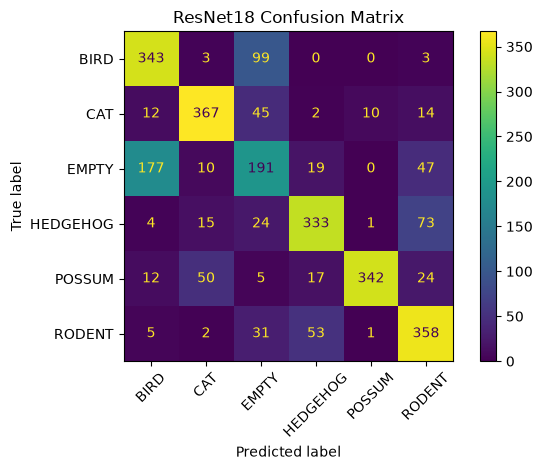

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_predictions,
    display_labels=CLASS_NAMES,
    xticks_rotation=45
)

plt.title("ResNet18 Confusion Matrix")
plt.tight_layout()
plt.show()